# NumPy

Arrays de NumPy: creación, forma, tipos, operaciones vectorizadas, indexación, cortes, números aleatorios y estadística (ejemplos del día 24 de *30 Days Of Python*).

## 1. Crear arrays

Crear arrays de enteros, reales, booleanos y bidimensionales a partir de listas y tuplas, y convertirlos de vuelta a lista.

In [1]:
import numpy as np

enteros = np.array([1, 2, 3, 4, 5])
reales = np.array([1, 2, 3], dtype=float)
booleanos = np.array([0, 1, -1, 0, 0], dtype=bool)
matriz = np.array([[0, 1, 2], [3, 4, 5], [6, 7, 8]])
desde_tupla = np.array((1, 2, 3))
print(enteros, reales, booleanos, desde_tupla)
print(matriz)
print(matriz.tolist())

[1 2 3 4 5] [1. 2. 3.] [False  True  True False False] [1 2 3]
[[0 1 2]
 [3 4 5]
 [6 7 8]]
[[0, 1, 2], [3, 4, 5], [6, 7, 8]]


## 2. Forma, tipo y tamaño

Mostrar `shape`, `dtype` y `size` y convertir tipos con `astype`.

In [2]:
print(enteros.shape, matriz.shape, enteros.dtype, reales.dtype, matriz.size)
print(np.array([1.9, 2.5, -3.7]).astype(int), np.array([1, 0, 3]).astype(bool), np.array(["1", "2"]).astype(int))

(5,) (3, 3) int64 float64 9
[ 1  2 -3] [ True False  True] [1 2]


## 3. Operaciones vectorizadas

Sumar, restar, multiplicar, dividir, módulo, división entera y potencia elemento a elemento sin bucles.

In [3]:
a = np.array([1, 2, 3, 4, 5])
print(a + 10, a - 10, a * 10, a / 10, a % 3, a // 3, a**2)

[11 12 13 14 15] [-9 -8 -7 -6 -5] [10 20 30 40 50] [0.1 0.2 0.3 0.4 0.5] [1 2 0 1 2] [0 0 1 1 1] [ 1  4  9 16 25]


## 4. Indexación, cortes e inversión

Acceder a filas, columnas y elementos de una matriz, recortar submatrices e invertir filas, columnas o toda la matriz.

In [4]:
print(matriz[0], matriz[:, 0], matriz[1, 2], matriz[0:2, 0:2])
print(matriz[::-1], matriz[:, ::-1], matriz[::-1, ::-1], sep="\n")

[0 1 2] [0 3 6] 5 [[0 1]
 [3 4]]
[[6 7 8]
 [3 4 5]
 [0 1 2]]
[[2 1 0]
 [5 4 3]
 [8 7 6]]
[[8 7 6]
 [5 4 3]
 [2 1 0]]


## 5. Valores ausentes, ceros, unos y forma

Representar valores ausentes con `np.nan`, crear arrays de ceros y unos, cambiar la forma con `reshape` y aplanar con `flatten`.

In [5]:
datos = np.array([1, 2, np.nan, 4])
print(np.isnan(datos), np.nanmean(datos))
print(np.zeros((2, 3)), np.ones((2, 3), dtype=int), sep="\n")
print(np.arange(12).reshape(3, 4), np.arange(12).reshape(3, 4).flatten(), sep="\n")
print(np.hstack([enteros, enteros]), np.vstack([enteros, enteros]), sep="\n")

[False False  True False] 2.3333333333333335
[[0. 0. 0.]
 [0. 0. 0.]]
[[1 1 1]
 [1 1 1]]
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
[ 0  1  2  3  4  5  6  7  8  9 10 11]
[1 2 3 4 5 1 2 3 4 5]
[[1 2 3 4 5]
 [1 2 3 4 5]]


## 6. Números aleatorios

Generar reales y enteros aleatorios, elegir elementos al azar y muestras de una distribución normal.

In [6]:
rng = np.random.default_rng(42)
print(rng.random(3), rng.integers(1, 10, size=5), rng.choice(["a", "b", "c"], size=4))
normal = rng.normal(79, 15, 80)
print(normal[:5].round(1))

[0.77395605 0.43887844 0.85859792] [1 7 2 1 5] ['c' 'c' 'c' 'c']
[78.7 66.2 92.2 90.7 80. ]


## 7. Estadística

Calcular mínimo, máximo, media, mediana, desviación típica, percentiles y la matriz de un producto, y crear secuencias con `arange` y `linspace`.

In [7]:
print(normal.min().round(1), normal.max().round(1), normal.mean().round(1), np.median(normal).round(1), normal.std().round(1))
print(np.percentile(normal, [25, 50, 75]).round(1))
print(matriz @ np.eye(3, dtype=int), np.dot([1, 2], [3, 4]))
print(np.arange(0, 20, 4), np.linspace(1.0, 5.0, num=5), np.logspace(2, 4, 3))

53.8 111.1 79.5 80.0 10.9
[72.  80.  87.9]
[[0 1 2]
 [3 4 5]
 [6 7 8]] 11
[ 0  4  8 12 16] [1. 2. 3. 4. 5.] [  100.  1000. 10000.]


## 8. Broadcasting

Crear sin bucles la tabla de multiplicar del 1 al 10 combinando un vector columna y un vector fila, y la matriz de distancias entre varios puntos del plano. NumPy compara las formas empezando por la derecha: dos dimensiones son compatibles si son iguales o una de ellas vale 1, que se estira para igualar a la otra. Comprobar los resultados con bucles y ver qué ocurre con formas incompatibles.

In [8]:
n = np.arange(1, 11)
tabla = n[:, None] * n  # (10, 1) * (10,) -> (10, 10)
print(n[:, None].shape, n.shape, tabla.shape)
print(tabla[:4, :6])
assert all(tabla[i - 1, j - 1] == i * j for i in range(1, 11) for j in range(1, 11))

puntos = np.array([[0, 0], [3, 4], [6, 8], [1, 1]])
diferencias = puntos[:, None, :] - puntos[None, :, :]  # (4, 1, 2) - (1, 4, 2) -> (4, 4, 2)
distancias = np.sqrt((diferencias**2).sum(axis=-1))
print(distancias.round(2))
assert np.allclose(distancias, [[np.hypot(*(p - q)) for q in puntos] for p in puntos])

try:
    np.ones((3, 2)) + np.ones(3)
except ValueError as e:
    print("ValueError:", e)

(10, 1) (10,) (10, 10)
[[ 1  2  3  4  5  6]
 [ 2  4  6  8 10 12]
 [ 3  6  9 12 15 18]
 [ 4  8 12 16 20 24]]
[[ 0.    5.   10.    1.41]
 [ 5.    0.    5.    3.61]
 [10.    5.    0.    8.6 ]
 [ 1.41  3.61  8.6   0.  ]]
ValueError: operands could not be broadcast together with shapes (3,2) (3,) 


## 9. Indexado booleano, avanzado y `np.where`

Con las temperaturas de 12 días: seleccionar las de más de 25 grados y las que están entre 0 y 10 con máscaras booleanas, contar las heladas y sus posiciones, elegir elementos por una lista de índices y una submatriz con `np.ix_`, y usar `np.where` para cambiar los valores negativos por 0 y clasificar cada día en frío, templado o calor.

In [9]:
rng = np.random.default_rng(0)
temperaturas = rng.integers(-5, 36, size=12)
print(temperaturas)
print(temperaturas[temperaturas > 25], temperaturas[(temperaturas >= 0) & (temperaturas <= 10)])
print((temperaturas < 0).sum(), np.flatnonzero(temperaturas < 0))
assert temperaturas[temperaturas > 25].tolist() == [t for t in temperaturas.tolist() if t > 25]

print(temperaturas[[0, 3, 3, -1]])
m = np.arange(16).reshape(4, 4)
# con dos listas se emparejan los índices: (0, 1) y (2, 3); np.ix_ cruza filas y columnas
print(m[[0, 2], [1, 3]], m[np.ix_([0, 2], [1, 3])], sep="\n")

sin_heladas = np.where(temperaturas < 0, 0, temperaturas)
copia = temperaturas.copy()
copia[copia < 0] = 0
assert np.array_equal(sin_heladas, copia)
print(sin_heladas)
print(np.where(temperaturas >= 25, "calor", np.where(temperaturas <= 5, "frío", "templado")))

[29 21 15  6  7 -4 -2 -5  2 28 21 32]
[29 28 32] [6 7 2]
3 [5 6 7]
[29  6  6 32]
[ 1 11]
[[ 1  3]
 [ 9 11]]
[29 21 15  6  7  0  0  0  2 28 21 32]
['calor' 'templado' 'templado' 'templado' 'templado' 'frío' 'frío' 'frío'
 'frío' 'calor' 'templado' 'calor']


## 10. Reducciones por ejes

Con las ventas de 4 tiendas (filas) durante 7 días (columnas): calcular el total de cada tienda (`axis=1`), el de cada día (`axis=0`) y el global, la tienda que más vende cada día y el mejor día de cada tienda, y el porcentaje de cada día sobre el total de su tienda usando `keepdims` para que el broadcasting funcione.

In [10]:
rng = np.random.default_rng(1)
ventas = rng.integers(10, 100, size=(4, 7))
print(ventas)
por_tienda, por_dia = ventas.sum(axis=1), ventas.sum(axis=0)
print(por_tienda, por_dia, ventas.sum())
print(ventas.argmax(axis=0), ventas.argmax(axis=1))
print(ventas.sum(axis=1).shape, ventas.sum(axis=1, keepdims=True).shape)
porcentajes = 100 * ventas / ventas.sum(axis=1, keepdims=True)
print(porcentajes.round(1))
assert por_tienda.tolist() == [sum(fila) for fila in ventas.tolist()]
assert por_dia.tolist() == [sum(columna) for columna in zip(*ventas.tolist())]
assert np.allclose(porcentajes.sum(axis=1), 100)

[[52 56 77 95 13 22 84]
 [95 32 38 88 48 34 84]
 [33 46 67 59 17 12 87]
 [77 85 58 83 39 50 80]]
[399 419 321 472] [257 219 240 325 117 118 335] 1611
[1 3 0 0 1 3 2] [3 0 6 1]
(4,) (4, 1)
[[13.  14.  19.3 23.8  3.3  5.5 21.1]
 [22.7  7.6  9.1 21.  11.5  8.1 20. ]
 [10.3 14.3 20.9 18.4  5.3  3.7 27.1]
 [16.3 18.  12.3 17.6  8.3 10.6 16.9]]


## 11. Álgebra lineal

Resolver el sistema $2x + y - z = 8$, $-3x - y + 2z = -11$, $-2x + y + 2z = -3$ con `np.linalg.solve`. Calcular el determinante y la inversa de la matriz de coeficientes y comprobar que $A^{-1}b$ da la misma solución y que $A A^{-1} = I$. Ver qué ocurre al invertir una matriz singular (determinante 0).

In [11]:
A = np.array([[2, 1, -1], [-3, -1, 2], [-2, 1, 2]], dtype=float)
b = np.array([8, -11, -3], dtype=float)
x = np.linalg.solve(A, b)
inversa = np.linalg.inv(A)
print(x, round(np.linalg.det(A), 6))
print(inversa.round(3))
assert np.allclose(A @ x, b) and np.allclose(inversa @ b, x) and np.allclose(A @ inversa, np.eye(3))

singular = np.array([[1, 2], [2, 4]], dtype=float)
print(np.linalg.det(singular))
try:
    np.linalg.inv(singular)
except np.linalg.LinAlgError as e:
    print("LinAlgError:", e)

[ 2.  3. -1.] -1.0
[[ 4.  3. -1.]
 [-2. -2.  1.]
 [ 5.  4. -1.]]
0.0
LinAlgError: Singular matrix


## 12. Vectorizar un bucle

Estimar $\pi$ con el método de Monte Carlo: se lanzan $n$ puntos al azar en el cuadrado unidad y la proporción que cae dentro del cuarto de círculo de radio 1 se acerca a $\pi/4$. Escribirlo con un bucle y vectorizado, comprobar que con la misma semilla de `default_rng` dan exactamente el mismo resultado, medir con `timeit` cuánto más rápida es la versión vectorizada y ver cómo mejora la estimación al aumentar $n$.

In [12]:
import timeit

def pi_bucle(n, semilla=0):
    rng = np.random.default_rng(semilla)
    dentro = 0
    for _ in range(n):
        x, y = rng.random(), rng.random()
        dentro += x * x + y * y <= 1
    return 4 * dentro / n

def pi_vectorizado(n, semilla=0):
    puntos = np.random.default_rng(semilla).random((n, 2))
    return 4 * np.count_nonzero((puntos**2).sum(axis=1) <= 1) / n

n = 100_000
assert pi_bucle(n) == pi_vectorizado(n)
t_bucle = min(timeit.repeat(lambda: pi_bucle(n), repeat=3, number=1))
t_vector = min(timeit.repeat(lambda: pi_vectorizado(n), repeat=3, number=1))
print(f"bucle {t_bucle * 1000:.1f} ms, vectorizado {t_vector * 1000:.2f} ms: {t_bucle / t_vector:.0f} veces más rápido")
for n in (10**2, 10**4, 10**6):
    estimacion = pi_vectorizado(n)
    print(f"n = {n:>9}: {estimacion:.5f}, error {abs(estimacion - np.pi):.5f}")

bucle 60.2 ms, vectorizado 1.56 ms: 39 veces más rápido
n =       100: 2.92000, error 0.22159
n =     10000: 3.14840, error 0.00681
n =   1000000: 3.14117, error 0.00042


## 13. Imágenes como matrices

Una imagen en escala de grises es una matriz de brillos entre 0 y 1, y una en color un array de forma `(alto, ancho, 3)` con los canales rojo, verde y azul. Crear un degradado horizontal, un círculo con broadcasting y una imagen en color que los combine; después rotarla con `np.rot90`, voltearla con `np.flipud` y `np.fliplr` y comprobar que equivalen a cortes con paso −1. Mostrar todas las imágenes.

(100, 150) (100, 150, 3) (150, 100, 3)


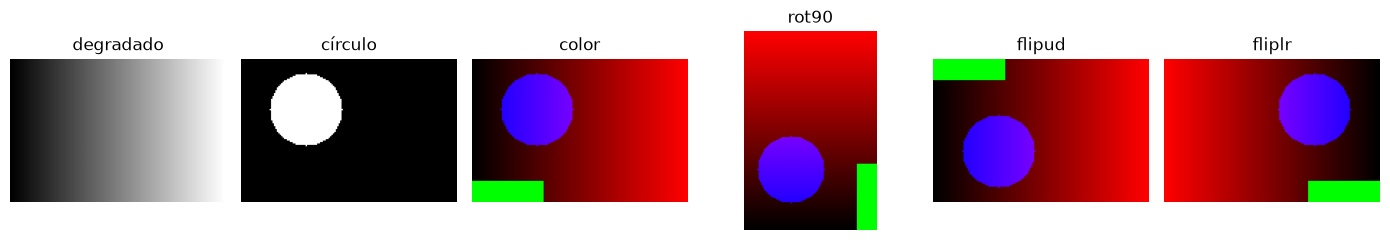

In [13]:
import matplotlib.pyplot as plt

alto, ancho = 100, 150
degradado = np.tile(np.linspace(0, 1, ancho), (alto, 1))
y, x = np.ogrid[:alto, :ancho]  # (100, 1) y (1, 150)
circulo = ((x - 45) ** 2 + (y - 35) ** 2 <= 25**2).astype(float)
color = np.zeros((alto, ancho, 3))
color[..., 0] = degradado
color[..., 2] = circulo
color[-15:, :50] = [0, 1, 0]  # franja verde abajo a la izquierda para ver la orientación

assert np.array_equal(np.flipud(color), color[::-1]) and np.array_equal(np.fliplr(color), color[:, ::-1])
assert np.array_equal(np.rot90(color, 2), color[::-1, ::-1]) and np.array_equal(np.rot90(color, 4), color)
print(degradado.shape, color.shape, np.rot90(color).shape)

imagenes = {"degradado": degradado, "círculo": circulo, "color": color,
            "rot90": np.rot90(color), "flipud": np.flipud(color), "fliplr": np.fliplr(color)}
fig, ejes = plt.subplots(1, 6, figsize=(14, 2.5))
for eje, (titulo, imagen) in zip(ejes, imagenes.items()):
    eje.imshow(imagen, cmap="gray", vmin=0, vmax=1)
    eje.set_title(titulo)
    eje.axis("off")
plt.tight_layout()
plt.show()